# 2. Data-Driven Scales, Grid-Free Alpha Domain & Extended Persistence

**What you will learn:**
1. How the geometric **scale ladder** $\sigma_1 < \dots < \sigma_4$ (`3.37` to `10.47 cm`) is derived directly from inter-robot distances and swarm diameter **without any label** — and why capping ($k=10$) prevents smooth collapse.
2. How each run builds its own **grid-free domain** at scale $\sigma_m$ from three seed families (`robot coreset`, `near-critical barycenters`, `J = 0 skeleton`) + alpha complex at radius $(3\sigma)^2$.
3. Intuition for **Extended Persistence**: sweeping sublevel sets upward and superlevel sets downward so *every* minimum, peak, and saddle receives a finite birth–death coordinate in the six diagrams $(\mathrm{Ord}_0, \mathrm{Ord}_1, \mathrm{Rel}_1, \mathrm{Rel}_2, \mathrm{Ext}_0, \mathrm{Ext}_1)$.
4. Live GUDHI verification matching the stored Stage-2 diagrams bit-for-bit.

In [1]:
import pickle, sys
from pathlib import Path
from IPython.display import Image, display
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path[:0] = [str(ROOT / "analysis"), str(ROOT / "src"), str(ROOT)]

import figlib as L
import make_figures as M
L.style()

PAPER = ROOT / "results" / "epuck" / "paper"
RES = ROOT / "results" / "epuck"
load = lambda p: pickle.load(open(p, "rb"))

## 1. The Label-Free Scale Ladder ($M = 4$ Widths)

$$\sigma_{\min} = \max\!\left(\frac{d_{\min}}{2},\,\epsilon_\sigma\right), \qquad \sigma_{\max} = \frac{D_s}{2.35\,k}, \qquad \sigma_m = \sigma_{\min}\left(\frac{\sigma_{\max}}{\sigma_{\min}}\right)^{\frac{m-1}{M-1}}.$$

* $\sigma_{\min}$ resolves closest robot encounters ($d_{\min}$, floored by tracking precision $\epsilon_\sigma = 1\text{ cm}$).
* An uncapped ladder reaching $D_s / 2.35$ (`~1.05 m`) wipes out all internal trajectories into a single featureless bump (`figA_uncapped`). With $k=10$, $\sigma_4 = 10.47\text{ cm}$ captures arena-scale traffic without erasing local topology.

Geometric ladder widths (cm): [ 3.37  4.92  7.18 10.47]  | common ratio: 1.459


saved /home/ndinga/Documents/paper_topological_kinematics/figures/fig_scales.pdf


saved /home/ndinga/Documents/paper_topological_kinematics/figures/figA_uncapped.pdf


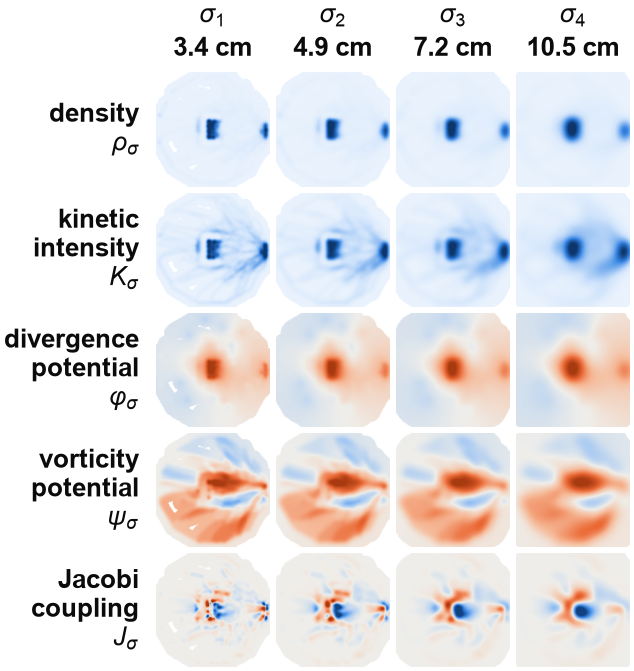

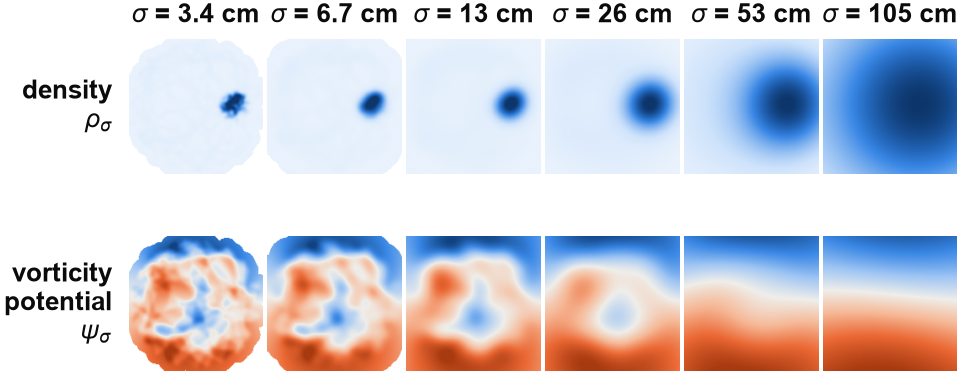

In [2]:
ladder = np.asarray(load(RES / "scale_ladder.pkl")["ladder"])
print("Geometric ladder widths (cm):", np.round(100 * ladder, 2), " | common ratio:", round(float(ladder[1]/ladder[0]), 3))

M.fig_scales(); M.fig_uncapped()
display(Image(filename=str(ROOT / "figures/fig_scales.png"), width=680))
display(Image(filename=str(ROOT / "figures/figA_uncapped.png"), width=880))

## 2. Grid-Free Alpha Domain (No Pixel Discretization Bias)

Rather than sampling fields onto a fixed Cartesian grid, Stage 1 builds an adaptive **3-family point cloud** per recording and scale:
1. **Farthest-point coreset** of observed robot positions (`epsilon = sigma_m / 2`) covering all trajectories.
2. **Near-critical seeds**: barycenters of the `5%` flattest Delaunay triangles of each field.
3. **Coupling skeleton**: up to `150` zeros along $J_\sigma = 0$ localized via bisection on Delaunay edges.

Let's inspect the full domain of the Shelter exemplar at $\sigma_3$ alongside a zoomed inset around the central shelter!

Total seeds: 1588 -> 1073 robot coreset, 329 near-critical, 186 on J=0 skeleton


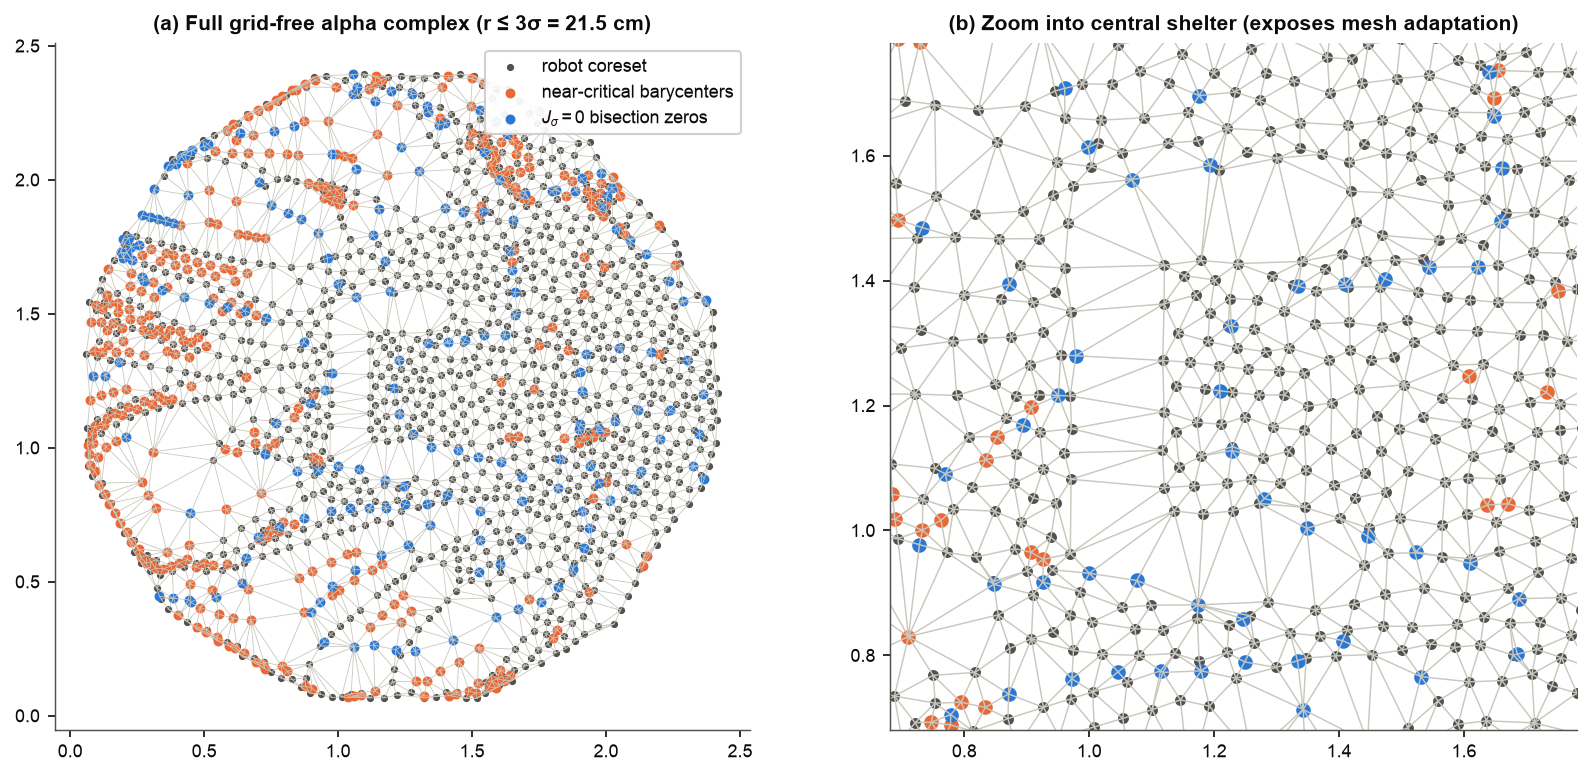

In [3]:
import gudhi
d = load(PAPER / "top1_tracks.pkl")
tax = load(PAPER / "taxonomy.pkl")[1]
ex_by_m = {int(d["labels"][e]): int(e) for e in tax["exemplars"]}
e = ex_by_m[3]  # Shelter
si = 2; sig = float(ladder[si])
st1 = load(RES / "stage1_alpha_fields" / f"traj{int(d['idx'][e]):04d}_s{si}.pkl")
seeds = st1["seeds"]
core, bary, skel = M._seed_families(seeds, np.asarray(st1["fields"]["J"]), d["tracks"][e]["pos"])
print(f"Total seeds: {len(seeds)} -> {core.sum()} robot coreset, {bary.sum()} near-critical, {skel.sum()} on J=0 skeleton")

st = gudhi.AlphaComplex(points=seeds).create_simplex_tree(max_alpha_square=(3 * sig) ** 2)
segs = np.asarray([seeds[s] for s, _ in st.get_skeleton(1) if len(s) == 2])

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(11.2, 5.2))
for ax, zoom in ((ax0, False), (ax1, True)):
    ax.add_collection(LineCollection(segs, colors="#c9c8be", linewidths=0.4 if not zoom else 0.7))
    ax.scatter(*seeds[core].T, s=6 if not zoom else 18, c=L.INK2, label="robot coreset")
    ax.scatter(*seeds[bary].T, s=14 if not zoom else 36, c=L.MCOL[1], label="near-critical barycenters")
    ax.scatter(*seeds[skel].T, s=14 if not zoom else 36, c=L.MCOL[0], label="$J_\\sigma=0$ bisection zeros")
    ax.set_aspect("equal")
    if not zoom:
        ax.set_title(f"(a) Full grid-free alpha complex (r ≤ 3σ = {300*sig:.1f} cm)", fontsize=10, fontweight="bold")
        ax.legend(loc="upper right", fontsize=8.5, framealpha=0.92)
    else:
        cx, cy = L.ARENA / 2, L.ARENA / 2
        ax.set_xlim(cx - 0.55, cx + 0.55); ax.set_ylim(cy - 0.55, cy + 0.55)
        ax.set_title("(b) Zoom into central shelter (exposes mesh adaptation)", fontsize=10, fontweight="bold")
plt.tight_layout(); plt.show()

## 3. Intuition: Sublevel + Superlevel Sweeps $\rightarrow$ Extended Persistence

Ordinary persistence tracks features born in sublevel sets $\{f \le c\}$, leaving global features (highest peak / global minimum) paired with $+\infty$. **Extended persistence** (`Cohen-Steiner et al., 2009`) follows the upward sweep by a downward superlevel sweep so every critical structure closes into a finite point $(b, d)$ across six sub-diagrams:
* **`Ord_0` / `Ord_1`**: connected wells merging / sublevel loops filled during the upward sweep ($b < d$).
* **`Rel_1` / `Rel_2`**: peaks merging / relative 2-cycles during the downward sweep ($b > d$).
* **`Ext_0` / `Ext_1`**: global min-to-max span & topological holes of the domain.

Let's visualize this live on a simple synthetic double-peak landscape before checking real swarm fields!

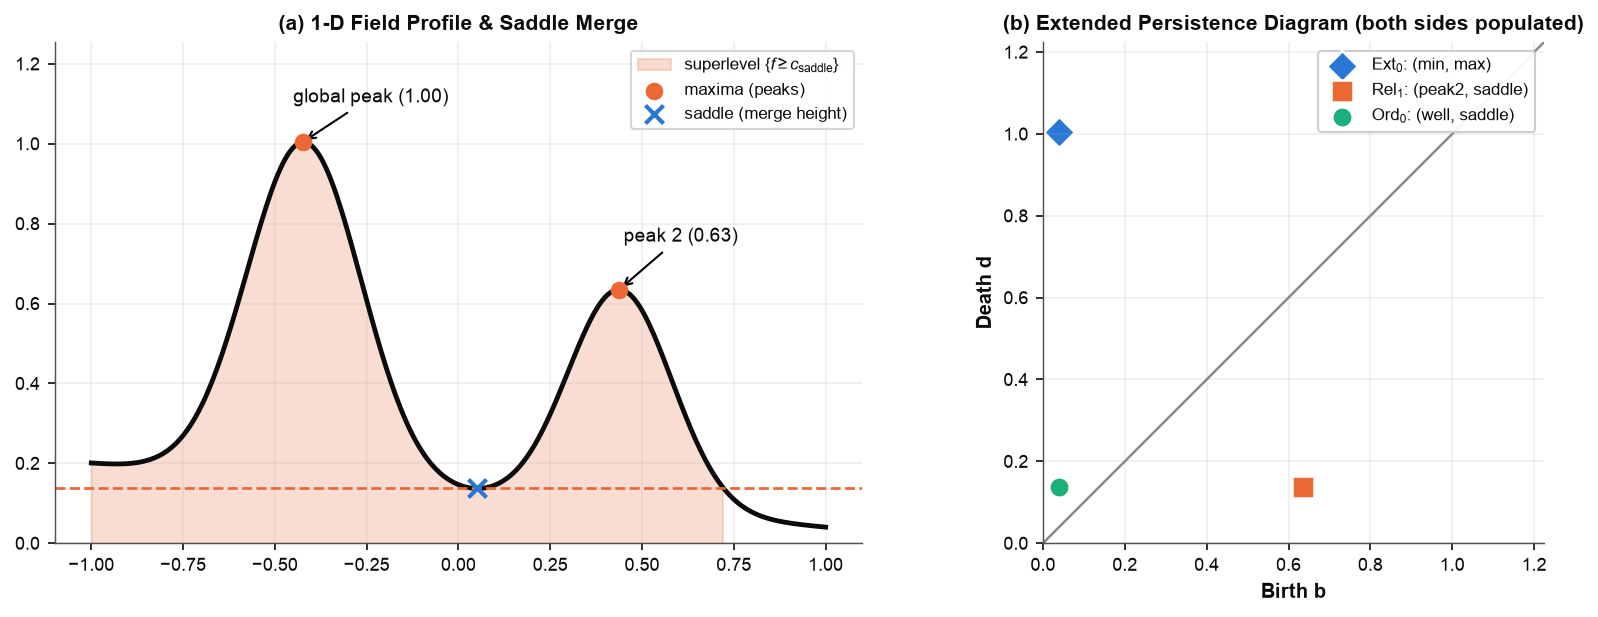

In [4]:
x = np.linspace(-1.0, 1.0, 300)
fx = 0.85 * np.exp(-((x + 0.42)/0.22)**2) + 0.55 * np.exp(-((x - 0.44)/0.20)**2) - 0.08 * x + 0.12
i_p1 = int(np.argmax(fx[:150]))
i_p2 = 150 + int(np.argmax(fx[150:]))
i_sad = i_p1 + int(np.argmin(fx[i_p1:i_p2]))
h_min, h_sad, h_p2, h_p1 = float(fx.min()), float(fx[i_sad]), float(fx[i_p2]), float(fx[i_p1])

fig, (ax_f, ax_d) = plt.subplots(1, 2, figsize=(11.5, 4.2))
ax_f.plot(x, fx, color=L.INK, lw=2.3)
ax_f.fill_between(x, 0, fx, where=(fx >= h_sad), color=L.MCOL[1], alpha=0.22, label=r"superlevel $\{f \geq c_{\mathrm{saddle}}\}$")
ax_f.axhline(h_sad, color=L.MCOL[1], ls="--", lw=1.3)
ax_f.scatter([x[i_p1], x[i_p2]], [h_p1, h_p2], c=L.MCOL[1], s=55, zorder=5, label="maxima (peaks)")
ax_f.scatter([x[i_sad]], [h_sad], c=L.MCOL[0], marker="x", s=75, lw=2, zorder=5, label="saddle (merge height)")
ax_f.annotate(f"peak 2 ({h_p2:.2f})", xy=(x[i_p2], h_p2), xytext=(0.45, h_p2 + 0.12), arrowprops=dict(arrowstyle="->"), fontsize=9)
ax_f.annotate(f"global peak ({h_p1:.2f})", xy=(x[i_p1], h_p1), xytext=(-0.45, h_p1 + 0.10), arrowprops=dict(arrowstyle="->"), fontsize=9)
ax_f.set_ylim(0, h_p1 + 0.25); ax_f.set_title("(a) 1-D Field Profile & Saddle Merge", fontweight="bold")
ax_f.legend(loc="upper right", fontsize=8); ax_f.grid(alpha=0.2)

lo, hi = 0.0, h_p1 + 0.22
ax_d.plot([lo, hi], [lo, hi], color="#8a8984", lw=1.2)
ax_d.scatter([h_min], [h_p1], s=110, marker="D", fc=L.MCOL[0], ec="white", lw=1.2, label=r"$\mathrm{Ext}_0$: (min, max)")
ax_d.scatter([h_p2], [h_sad], s=110, marker="s", fc=L.MCOL[1], ec="white", lw=1.2, label=r"$\mathrm{Rel}_1$: (peak2, saddle)")
ax_d.scatter([h_min], [h_sad], s=95, marker="o", fc=L.MCOL[2], ec="white", lw=1.2, label=r"$\mathrm{Ord}_0$: (well, saddle)")
ax_d.set_xlim(lo, hi); ax_d.set_ylim(lo, hi); ax_d.set_aspect("equal")
ax_d.set_xlabel("Birth b"); ax_d.set_ylabel("Death d")
ax_d.set_title("(b) Extended Persistence Diagram (both sides populated)", fontweight="bold")
ax_d.legend(loc="upper right", fontsize=8, framealpha=0.95); ax_d.grid(alpha=0.2)
plt.tight_layout(); plt.show()

## 4. Real Extended Persistence Diagrams & Exact GUDHI Verification

Now let's plot the six extended persistence diagrams for **all five fields** of the Shelter exemplar at $\sigma_3$ and recompute $\rho_\sigma$'s diagrams from raw seeds to prove exact identity with the stored Stage-2 output.

Diagram point counts per field (Shelter exemplar, sigma_3):
  rho : Ord0: 24  Ord1: 20  Rel1: 19  Rel2: 16  Ext0:  1  Ext1:  0
  K   : Ord0: 33  Ord1: 28  Rel1: 27  Rel2: 20  Ext0:  1  Ext1:  0
  phi : Ord0:  5  Ord1:  4  Rel1:  3  Rel2:  6  Ext0:  1  Ext1:  0
  psi : Ord0: 19  Ord1:  5  Rel1:  8  Rel2:  8  Ext0:  1  Ext1:  0
  J   : Ord0: 35  Ord1: 29  Rel1: 32  Rel2: 29  Ext0:  1  Ext1:  0


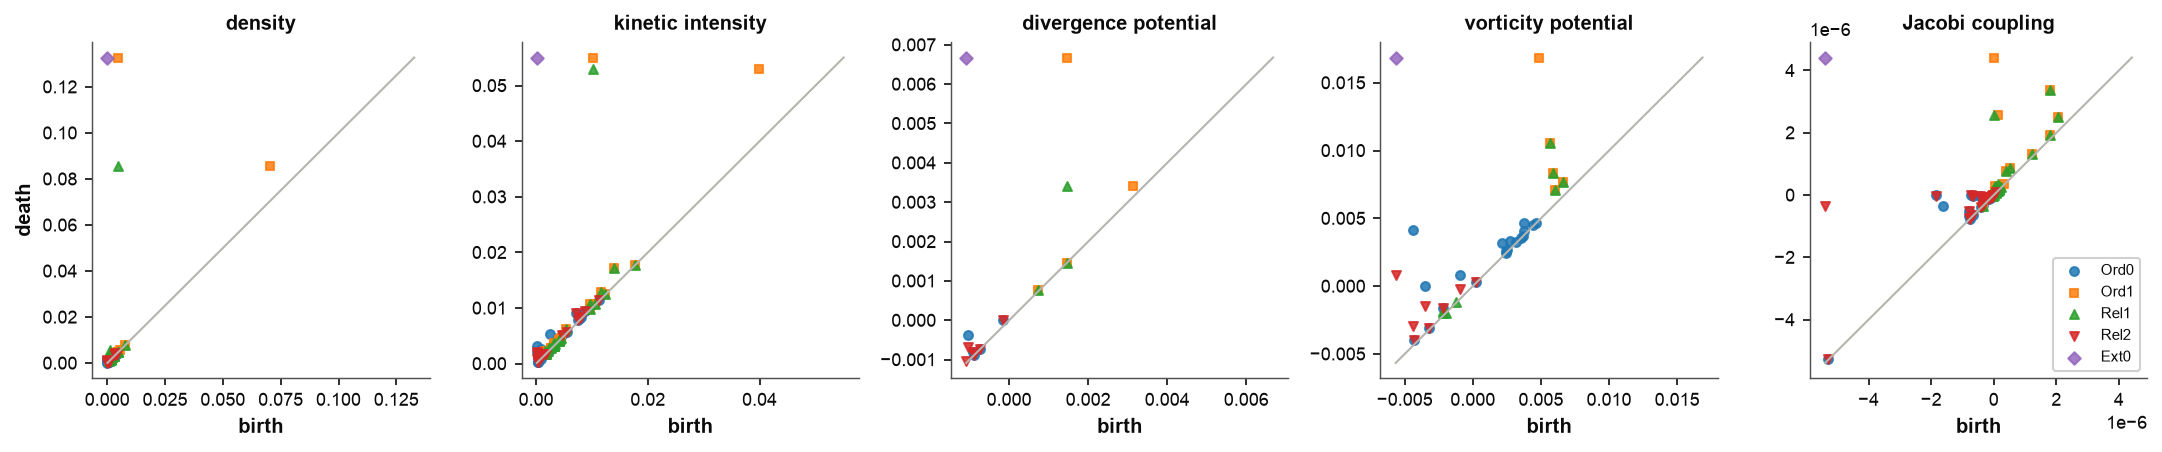

Recomputed rho diagrams match Stage 2 storage bit-for-bit: True


In [5]:
from gaussian_splatting.alpha import AlphaSimplexTree
from gaussian_splatting.persistence import PersistenceComputer

st2 = load(RES / "stage2_alpha_dgms" / f"traj{int(d['idx'][e]):04d}_s{si}.pkl")["dgms"]
names = ["Ord0", "Ord1", "Rel1", "Rel2", "Ext0", "Ext1"]

print("Diagram point counts per field (Shelter exemplar, sigma_3):")
for f in L.FIELDS:
    print(f"  {f:4s}: " + "  ".join(f"{n}:{len(x):3d}" for n, x in zip(names, st2[f])))

fig, axes = plt.subplots(1, 5, figsize=(14.5, 3.1))
for ax, f in zip(axes, L.FIELDS):
    allv = np.concatenate([np.asarray(x).ravel() for x in st2[f] if len(x)])
    lo, hi = allv.min(), allv.max()
    ax.plot([lo, hi], [lo, hi], color="#b5b4ae", lw=1.0)
    for k, x in enumerate(st2[f]):
        x = np.asarray(x)
        if len(x):
            ax.scatter(x[:, 0], x[:, 1], s=18, marker=M.DGM_MARK[k], alpha=0.85, label=names[k])
    ax.set_title(L.FNAME[f], fontsize=9.5, fontweight="bold")
    ax.set_xlabel("birth")
axes[0].set_ylabel("death"); axes[-1].legend(fontsize=7.2, loc="lower right", framealpha=0.92)
plt.tight_layout(); plt.show()

pc = PersistenceComputer(AlphaSimplexTree(seeds, alpha_sq_max=(3 * sig) ** 2))
dg = pc.compute_field(np.asarray(st1["fields"]["rho"]))
exact_ok = all(np.allclose(np.sort(a, 0), np.sort(np.asarray(b), 0)) for a, b in zip(dg, st2["rho"]))
print("Recomputed rho diagrams match Stage 2 storage bit-for-bit:", exact_ok)